# Figure 3: Magnitude-dependent scatter

Compute scatter in bins of native, pre-noise HSC aperture magnitude. These diagnostics describe the selected spectroscopic test subset.

Run all cells in a Python environment with `requirements/notebooks.txt` installed. The plotting style follows SpenderQ methods_paper and requires latex and dvipng. Inputs are frozen, documented snapshots in `paper/data/`; no training or network access is required. The final cell writes both PDF and PNG versions into `paper/figures/`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'paper/data/predictions.npz').exists())
sys.path.insert(0, str(ROOT / 'src'))
from pzflow.paper_utils import (COLORS, LABELS, set_style, load_predictions,
                         load_metrics, summary, bootstrap, save_figure)
set_style()

In [2]:
d = load_predictions(ROOT)
names = ['cosmos_pdf_flow', 'broadband_spec_flow', 'eazy_rprior', 'lephare_full_cosmos']
edges = [-np.inf, 22.5, 24., 24.5, 25.]
masks = [(d['imag'] >= lo) & (d['imag'] < hi) for lo, hi in zip(edges[:-1], edges[1:])]
counts = [int(m.sum()) for m in masks]
effective_magnitudes = np.array([np.median(d['imag'][m]) for m in masks])
print('Spec test counts by magnitude:', counts)
print('Effective magnitudes (median of each bin):', effective_magnitudes)
result = {}
for name in names:
    rows = []
    for b, mask in enumerate(masks):
        z, q = d['zspec'][mask], d[f'{name}_quantiles'][mask]
        rows.append((summary(z, q), bootstrap(z, q, seed=20261117 + b, n_boot=200)))
    result[name] = rows
    print(name, [round(row[0]['sigma_nmad'], 4) for row in rows])

Spec test counts by magnitude: [2203, 2378, 337, 165]
Effective magnitudes (median of each bin): [21.6496286  23.1654891  24.23575985 24.71055415]
cosmos_pdf_flow [0.0157, 0.0175, 0.0316, 0.0417]
broadband_spec_flow [0.0179, 0.0213, 0.0466, 0.0773]
eazy_rprior [0.0234, 0.0308, 0.0551, 0.0888]


lephare_full_cosmos [0.0076, 0.011, 0.0206, 0.0291]


Shaded bands join the 95% pointwise galaxy-bootstrap interval endpoints, using fill_between with alpha=0.5 and the same resampling seed for each method within a bin. Text labels give the number of spectroscopic test galaxies in each bin. The x-axis is numerical HSC i magnitude, with each point at the median magnitude of the test galaxies in its bin. Every method uses exactly the same x-coordinates, with no horizontal offsets. The bins describe only the available spectroscopic test galaxies.

Saved paper/figures/fig04_magnitude_dependence.pdf and .png


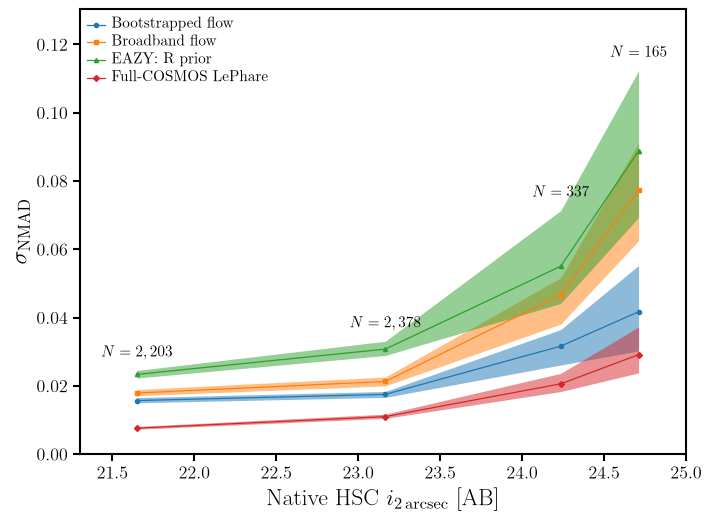

In [3]:
fig, ax = plt.subplots(figsize=(3.5, 2.55), layout='constrained')
positions = effective_magnitudes
markers = ['o', 's', '^', 'D']
for index, name in enumerate(names):
    x = positions
    y = np.array([r[0]['sigma_nmad'] for r in result[name]])
    ci = np.array([r[1]['sigma_nmad'] for r in result[name]])
    ax.fill_between(x, ci[:, 0], ci[:, 1], alpha=.5,
                    color=COLORS[name], linewidth=0)
    ax.plot(x, y, marker=markers[index], ms=3, lw=.9,
            color=COLORS[name], label=LABELS[name])
upper_envelope = np.max(np.array([[r[1]['sigma_nmad'][1] for r in result[name]]
                                 for name in names]), axis=0)
for x, upper, count in zip(positions, upper_envelope, counts):
    ax.annotate(f'$N={count:,}$', xy=(x, upper), xytext=(0, 8),
                textcoords='offset points', ha='center', va='bottom')
ax.set_xlim(21.3, 25.)
ax.set_xticks(np.arange(21.5, 25.01, .5))
ax.set_xlabel(r'Native HSC $i_{\mathrm{2\,arcsec}}$ [AB]')
ax.set(ylim=(0, upper_envelope.max()*1.16), ylabel=r'$\sigma_{\mathrm{NMAD}}$')
ax.legend(frameon=False, fontsize=6.2, loc='upper left')
save_figure(fig, ROOT, 'fig04_magnitude_dependence')
plt.show()
plt.close(fig)